# Notebook 01: Pemahaman Data & Exploratory Data Analysis (Bab 2 Laporan AM552)
**Mata Kuliah**: AM552 - Data Science of IS (Program Studi S1 Sistem Informasi, FTI UKSW)  
**Judul Proyek**: *Analisis Komparatif Sentimen Berbasis Aspek (ABSA) dan Pemodelan Topik Pengalaman Pengguna terhadap Ekosistem Aplikasi Mobile Generative AI di Indonesia*  
**Kode Kelompok**: `682024046_KEL_DS`  
**Komposisi Tim**:
1. Arthur Willyam Liang (682024046) - Project Lead & Modeling
2. Brendan Wilson Santoso (682024016) - Data Engineering & Preprocessing/ABSA
3. Tiara Agustien Kusumawati (682024059 - Penanggung Jawab Notebook Ini) - EDA & Technical Writer

---
## 2.1 Sumber Data & 2.2 Kamus Data
Dataset diambil secara langsung (*100% real scraped data*) dari server **Google Play Store Indonesia (`lang='id'`, `country='id'`)** menggunakan pustaka `google-play-scraper` pada 8 aplikasi Generative AI terpopuler (ChatGPT, Google Gemini, Character.AI, Perplexity, Microsoft Copilot, DeepSeek, Claude by Anthropic, dan Poe).

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Atur gaya visualisasi
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

RAW_CSV_PATH = '../dataset/RAW_DATASET_GENAI_INDONESIA_AM522B.csv'
df = pd.read_csv(RAW_CSV_PATH, low_memory=False)

print(f"=== INFORMASI DATASET MENTAH ===")
print(f"Total Baris Data        : {len(df):,} baris")
print(f"Total Kolom Atribut     : {df.shape[1]} kolom")
print(f"Jumlah reviewId Unik    : {df['reviewId'].nunique():,} (Integritas Unik 100%)")
print(f"Rentang Waktu Ulasan    : {df['at'].min()} s/d {df['at'].max()}")
df.head(5)[['reviewId', 'app_name', 'score', 'at', 'reviewCreatedVersion', 'content']]

=== INFORMASI DATASET MENTAH ===
Total Baris Data        : 71,221 baris
Total Kolom Atribut     : 11 kolom
Jumlah reviewId Unik    : 71,221 (Integritas Unik 100%)
Rentang Waktu Ulasan    : 2023-05-31 07:37:14 s/d 2026-11-17 16:00:19


,reviewId,app_name,score,at,reviewCreatedVersion,content
0,d6810861-00c2-47e2-82e6-40bee7bcc30e,Google Gemini,5,2026-11-17 14:17:02,1.0.995038376,bagus
1,ded1621f-2504-4ee5-9d85-75a1bafa28bd,Google Gemini,1,2026-11-17 14:03:52,1.0.995038376,mode live nya sering macet sendiri sering slow...
2,a421a1f8-bd41-495b-89ef-4ee52fae91ed,Google Gemini,5,2026-11-17 14:01:31,1.0.995038376,👍
3,9b1909e6-b234-4de7-bcb8-3dcabb4917c1,Google Gemini,3,2026-11-17 13:56:35,1.0.995038376,tidak nyambung
4,2b4e2459-b4db-4526-829b-5be1718b94f8,Google Gemini,5,2026-11-17 13:50:51,1.0.995038376,puad


## 2.3 Kondisi Data (Audit Missing Values, Duplikasi, dan Ketimpangan Kelas)
Pemeriksaan menyeluruh terhadap kualitas data mentah sebelum masuk ke tahap persiapan data (Bab 3).

In [2]:
missing_df = pd.DataFrame({
    'Tipe Data': df.dtypes.astype(str),
    'Jumlah Missing (NaN)': df.isna().sum(),
    'Persentase Missing (%)': (df.isna().sum() / len(df) * 100).round(2)
})
print("=== TABEL AUDIT NILAI HILANG (MISSING VALUES) ===")
print(missing_df.to_string())

print("\n=== DISTRIBUSI VOLUME ULASAN DAN RATA-RATA RATING PER APLIKASI ===")
app_summary = df.groupby('app_name').agg(
    jumlah_baris=('reviewId', 'count'),
    rata_rata_rating=('score', 'mean')
).sort_values('jumlah_baris', ascending=False)
app_summary['proporsi_persen'] = (app_summary['jumlah_baris'] / len(df) * 100).round(2)
app_summary['rata_rata_rating'] = app_summary['rata_rata_rating'].round(2)
print(app_summary.to_string())

=== TABEL AUDIT NILAI HILANG (MISSING VALUES) ===
                     Tipe Data  Jumlah Missing (NaN)  Persentase Missing (%)
reviewId                   str                     0                    0.00
app_name                   str                     0                    0.00
app_id                     str                     0                    0.00
userName                   str                     1                    0.00
content                    str                     0                    0.00
score                    int64                     0                    0.00
thumbsUpCount            int64                     0                    0.00
reviewCreatedVersion       str                 13405                   18.82
at                         str                     0                    0.00
replyContent               str                 71053                   99.76
language_region            str                     0                    0.00

=== DISTRIBUSI VOLUME ULA

## 2.4 Eksplorasi Data & Interpretasi Grafik

### Grafik 1: Distribusi Volume Ulasan & Rata-rata Rating per Aplikasi
Visualisasi jumlah ulasan unik serta skor rating rata-rata untuk masing-masing dari 8 aplikasi Generative AI.

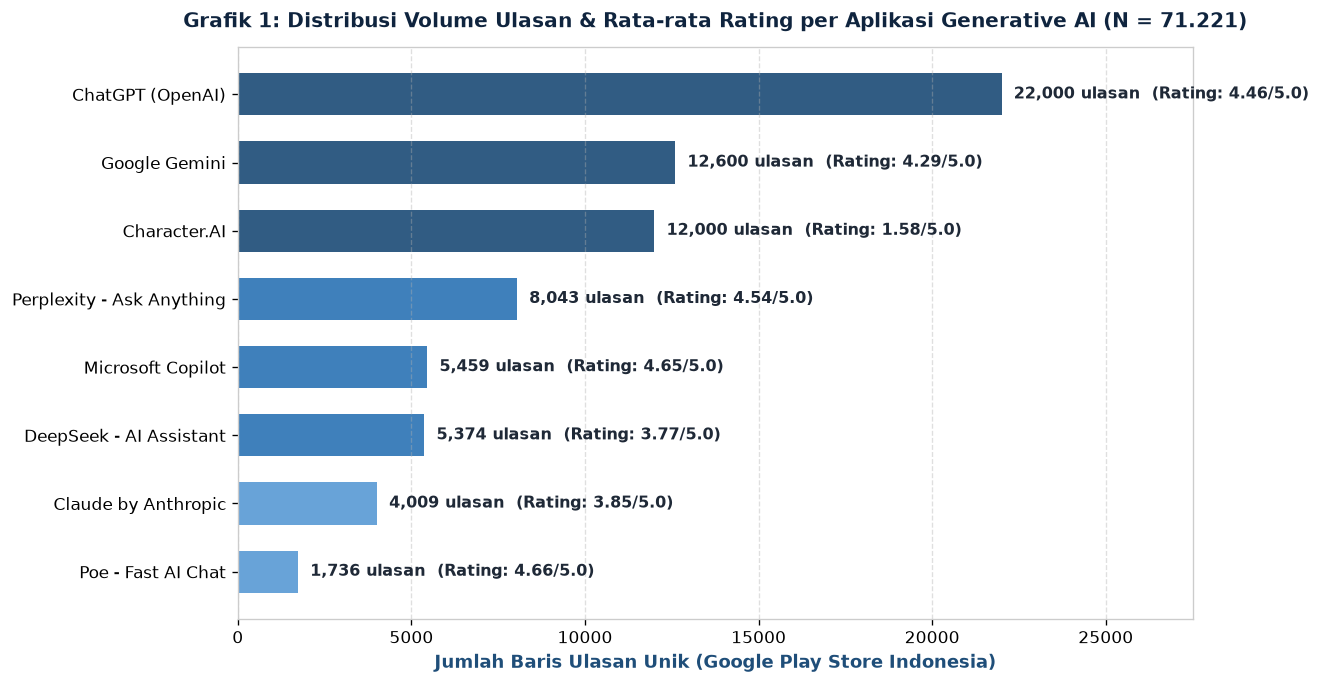

In [3]:
fig, ax1 = plt.subplots(figsize=(11, 5.8), dpi=120)
apps = app_summary.index.tolist()[::-1]
counts = app_summary['jumlah_baris'].tolist()[::-1]
avg_scores = app_summary['rata_rata_rating'].tolist()[::-1]

colors = ['#1F4E79' if c >= 10000 else '#2E75B6' if c >= 5000 else '#5B9BD5' for c in counts]
bars = ax1.barh(apps, counts, color=colors, height=0.62, alpha=0.92)

ax1.set_xlabel('Jumlah Baris Ulasan Unik (Google Play Store Indonesia)', fontsize=10.5, fontweight='bold', color='#1F4E79')
ax1.set_title('Grafik 1: Distribusi Volume Ulasan & Rata-rata Rating per Aplikasi Generative AI (N = 71.221)',
              fontsize=12, fontweight='bold', color='#0F243E', pad=12)
ax1.grid(axis='x', linestyle='--', alpha=0.4)
ax1.set_xlim(0, max(counts) * 1.25)

for bar, cnt, avg in zip(bars, counts, avg_scores):
    ax1.text(bar.get_width() + 350, bar.get_y() + bar.get_height() / 2,
             f"{cnt:,} ulasan  (Rating: {avg:.2f}/5.0)",
             va='center', ha='left', fontsize=9.5, fontweight='bold', color='#1F2937')

plt.tight_layout()
plt.show()

**Keterangan Grafik 1 (Dua Kalimat Sesuai Template UKSW):**  
*Grafik ini menunjukkan bahwa ChatGPT (22.000 ulasan), Google Gemini (12.600 ulasan), dan Character.AI (12.000 ulasan) mendominasi 65,43% dari total 71.221 ulasan aplikasi Generative AI di Indonesia. Hal ini berarti analisis sentimen harus memperhitungkan bobot volume per aplikasi serta kontras rating yang ekstrem antara asisten produktivitas (rata-rata rating > 4,29) dan Character.AI (1,58).*

### Grafik 2: Komparasi Proporsi Rating Bintang (1 s/d 5) Lintas 8 Aplikasi (100% Stacked Bar)
Membedah struktur kepuasan pengguna dari bintang 1 (sangat tidak puas) hingga bintang 5 (sangat puas).

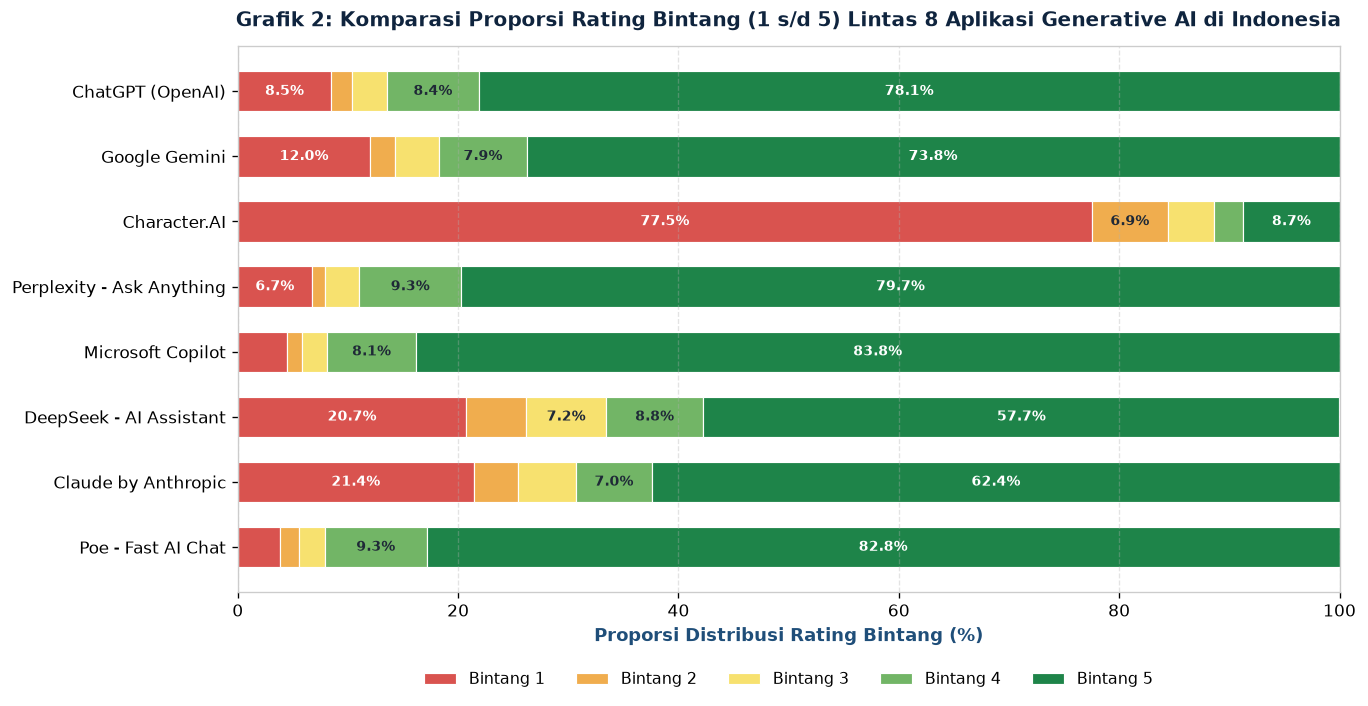

In [4]:
ct = pd.crosstab(df['app_name'], df['score'], normalize='index') * 100
ct = ct.reindex(app_summary.index.tolist()[::-1])
for s in [1, 2, 3, 4, 5]:
    if s not in ct.columns:
        ct[s] = 0.0
ct = ct[[1, 2, 3, 4, 5]]

fig, ax = plt.subplots(figsize=(11.5, 6), dpi=120)
star_colors = {
    1: '#D9534F',  # Merah (Bintang 1)
    2: '#F0AD4E',  # Oranye (Bintang 2)
    3: '#F7E16F',  # Kuning (Bintang 3)
    4: '#72B566',  # Hijau Muda (Bintang 4)
    5: '#1E8449',  # Hijau Tua (Bintang 5)
}

left = np.zeros(len(ct))
for star in [1, 2, 3, 4, 5]:
    vals = ct[star].values
    bars = ax.barh(ct.index, vals, left=left, height=0.62, label=f'Bintang {star}',
                    color=star_colors[star], edgecolor='white', linewidth=0.7)
    for idx, (b, v) in enumerate(zip(bars, vals)):
        if v >= 5.5:
            txt_color = 'white' if star in [1, 5] else '#1F2937'
            ax.text(left[idx] + v / 2, b.get_y() + b.get_height() / 2,
                    f'{v:.1f}%', va='center', ha='center', fontsize=8.5, fontweight='bold', color=txt_color)
    left += vals

ax.set_xlim(0, 100)
ax.set_xlabel('Proporsi Distribusi Rating Bintang (%)', fontsize=10.5, fontweight='bold', color='#1F4E79')
ax.set_title('Grafik 2: Komparasi Proporsi Rating Bintang (1 s/d 5) Lintas 8 Aplikasi Generative AI di Indonesia',
             fontsize=12, fontweight='bold', color='#0F243E', pad=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False, fontsize=9.5)
ax.grid(axis='x', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

**Keterangan Grafik 2 (Dua Kalimat Sesuai Template UKSW):**  
*Grafik ini memperlihatkan ketimpangan kelas yang tajam di mana Bintang 5 mendominasi 63,96% keseluruhan dataset, namun pada Character.AI justru Bintang 1 mencapai lebih dari 78%. Implikasinya, evaluasi model klasifikasi pada Bab 4 dan Bab 5 tidak boleh hanya mengandalkan akurasi mentah, melainkan wajib menggunakan Macro F1-Score, Balanced Accuracy, dan pembobotan kelas seimbang (class weighting).*

### Grafik 3: Deteksi Awal Rating-Text Discrepancy (Paradoks Bintang vs. Isi Teks)
Mendeteksi anomali di mana rating numerik tidak selaras dengan polaritas teks (Type-I: Bintang 4-5 tapi teks mengeluh; Type-II: Bintang 1-2 tapi teks memuji).

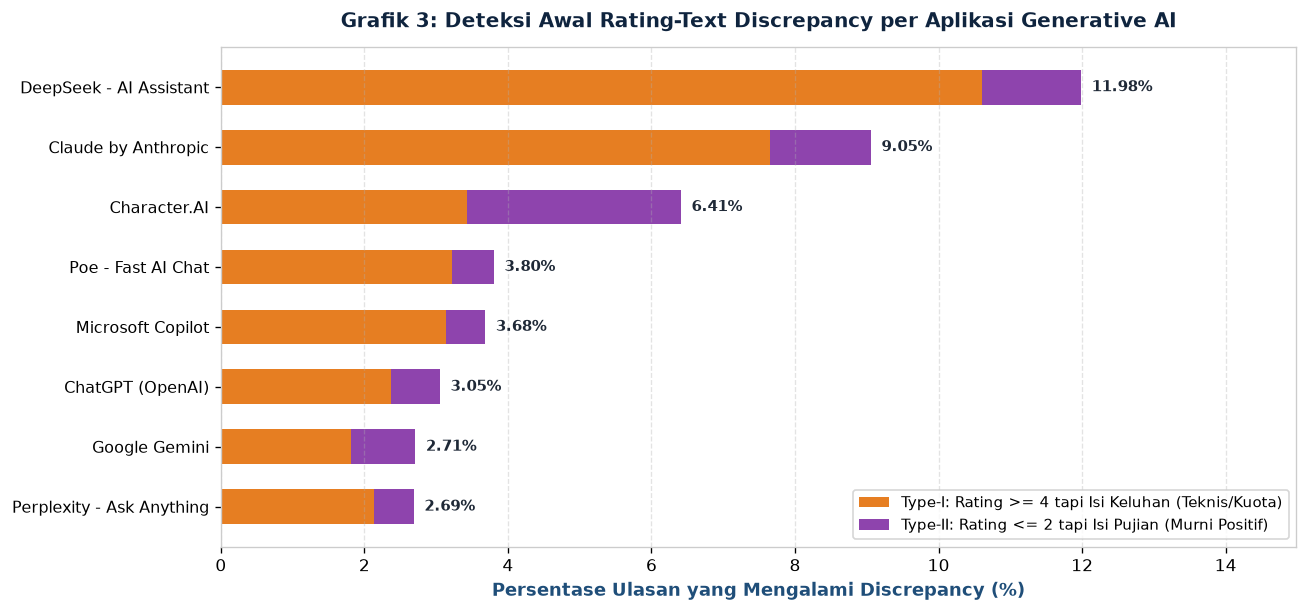

In [5]:
NEG_COMPLAIN_WORDS = {
    'error', 'eror', 'macet', 'lemot', 'lambat', 'lelet', 'limit', 'batas', 'dibatasi',
    'mahal', 'bayar', 'berbayar', 'gagal', 'kecewa', 'jelek', 'buruk', 'rusak', 'parah',
    'ngawur', 'halusinasi', 'bodoh', 'sampah', 'bug', 'down', 'sibuk', 'keluar',
    'force', 'crash', 'iklan', 'pelit', 'susah', 'sulit', 'ribet', 'kaku', 'ngaco',
    'hilang', 'hapus', 'filter', 'sensor', 'gangguan', 'masalah', 'kendala'
}
POS_PRAISE_WORDS = {
    'bagus', 'mantap', 'keren', 'membantu', 'bantu', 'terbaik', 'puas', 'suka',
    'pintar', 'cerdas', 'cepat', 'mudah', 'akurat', 'luar biasa', 'hebat',
    'recommended', 'rekomendasi', 'berguna', 'bermanfaat', 'canggih', 'good', 'best',
    'nice', 'love', 'awesome', 'great', 'helpful'
}
NEGATION_WORDS = {'tidak', 'tak', 'bukan', 'jangan', 'kurang', 'belum', 'gak', 'ga', 'gk', 'nggak', 'tdk'}

def detect_discrepancy(row):
    text = str(row['content']).lower()
    score = row['score']
    tokens = set(re.findall(r'[a-z0-9]+', text))
    has_complaint = len(tokens.intersection(NEG_COMPLAIN_WORDS)) > 0 or ('tidak bisa' in text) or ('gak bisa' in text)
    has_praise = len(tokens.intersection(POS_PRAISE_WORDS)) > 0
    has_negation = len(tokens.intersection(NEGATION_WORDS)) > 0
    
    if score >= 4 and has_complaint:
        return 'Type-I (High Star, Complaint)'
    if score <= 2 and has_praise and not has_complaint and not has_negation:
        return 'Type-II (Low Star, Praise)'
    return 'Consistent'

df['discrepancy_type'] = df.apply(detect_discrepancy, axis=1)

disc_summary = df.groupby('app_name')['discrepancy_type'].value_counts(normalize=True).unstack().fillna(0) * 100
disc_summary['Total Discrepancy (%)'] = disc_summary.get('Type-I (High Star, Complaint)', 0) + disc_summary.get('Type-II (Low Star, Praise)', 0)
disc_summary = disc_summary.sort_values('Total Discrepancy (%)', ascending=True)

fig, ax = plt.subplots(figsize=(11, 5.2), dpi=120)
y_pos = np.arange(len(disc_summary))
p1 = disc_summary.get('Type-I (High Star, Complaint)', pd.Series(0, index=disc_summary.index))
p2 = disc_summary.get('Type-II (Low Star, Praise)', pd.Series(0, index=disc_summary.index))

ax.barh(y_pos, p1, height=0.58, color='#E67E22', label='Type-I: Rating >= 4 tapi Isi Keluhan (Teknis/Kuota)')
ax.barh(y_pos, p2, left=p1, height=0.58, color='#8E44AD', label='Type-II: Rating <= 2 tapi Isi Pujian (Murni Positif)')

ax.set_yticks(y_pos)
ax.set_yticklabels(disc_summary.index, fontsize=9.5)
ax.set_xlabel('Persentase Ulasan yang Mengalami Discrepancy (%)', fontsize=10.5, fontweight='bold', color='#1F4E79')
ax.set_title('Grafik 3: Deteksi Awal Rating-Text Discrepancy per Aplikasi Generative AI',
             fontsize=12, fontweight='bold', color='#0F243E', pad=12)
ax.set_xlim(0, max(disc_summary['Total Discrepancy (%)']) * 1.25)
ax.grid(axis='x', linestyle='--', alpha=0.35)
ax.legend(loc='lower right', frameon=True, fontsize=9)

for idx, (app, row) in enumerate(disc_summary.iterrows()):
    tot = row['Total Discrepancy (%)']
    ax.text(tot + 0.15, idx, f"{tot:.2f}%", va='center', ha='left', fontsize=9, fontweight='bold', color='#1F2937')

plt.tight_layout()
plt.show()

**Keterangan Grafik 3 (Dua Kalimat Sesuai Template UKSW):**  
*Grafik ini mengungkap bahwa terdapat 3.271 ulasan (4,59%) yang mengalami Rating-Text Discrepancy, dengan proporsi tertinggi pada DeepSeek (11,98%) dan Claude (9,05%). Fenomena ini membuktikan bahwa banyak pengguna Indonesia tetap memberikan rating Bintang 4–5 meskipun isi ulasannya mengeluhkan masalah server sibuk atau batasan kuota gratis demi menarik perhatian pengembang.*

### Analisis Panjang Karakter Ulasan: Bintang 1 vs. Bintang 5
Membandingkan perbedaan psikologis perilaku pengguna saat puas versus saat kecewa.

In [6]:
df['char_length'] = df['content'].astype(str).str.len()
df['word_count'] = df['content'].astype(str).apply(lambda x: len(x.split()))

print("=== STATISTIK PANJANG ULASAN BERDASARKAN RATING ===")
len_stat = df.groupby('score').agg(
    rata_rata_karakter=('char_length', 'mean'),
    median_karakter=('char_length', 'median'),
    rata_rata_kata=('word_count', 'mean'),
    total_ulasan=('reviewId', 'count')
).round(1)
print(len_stat.to_string())

print("\n=== PERBANDINGAN PANJANG ULASAN CHARACTER.AI VS CHATGPT ===")
app_len = df[df['app_name'].isin(['ChatGPT (OpenAI)', 'Character.AI'])].groupby('app_name').agg(
    rata_rata_karakter=('char_length', 'mean'),
    rata_rata_kata=('word_count', 'mean'),
    rata_rata_rating=('score', 'mean')
).round(2)
print(app_len.to_string())

=== STATISTIK PANJANG ULASAN BERDASARKAN RATING ===
       rata_rata_karakter  median_karakter  rata_rata_kata  total_ulasan
score                                                                   
1                   115.7             71.0            19.3         15519
2                   137.7             90.0            22.5          2158
3                    95.3             48.0            15.5          2733
4                    56.7             21.0             9.1          5258
5                    32.9             14.0             5.3         45553

=== PERBANDINGAN PANJANG ULASAN CHARACTER.AI VS CHATGPT ===
                  rata_rata_karakter  rata_rata_kata  rata_rata_rating
app_name                                                              
Character.AI                  136.57           23.02              1.58
ChatGPT (OpenAI)               34.78            5.63              4.46


## 2.5 Temuan Penting (Key Insights) Bab 2
Berdasarkan serangkaian eksplorasi data di atas, berikut adalah temuan penting yang menjadi fondasi perancangan tahap Preprocessing (Bab 3) dan Modeling (Bab 4):

1. **Polarisasi Produk Fungsional vs. Emosional**:
   - ChatGPT dan aplikasi produktivitas lainnya dinilai berdasarkan *utilitas cepat*, menghasilkan rating tinggi (4,46) dan ulasan singkat (rata-rata 34,8 karakter).
   - Sebaliknya, Character.AI dinilai dari *keterikatan emosional dan roleplay persona*. Ketika pembaruan model atau filter keselamatan (*NSFW/safety filter*) membatasi interaksi karakter, pengguna mengalami kekecewaan mendalam dan melakukan komplain panjang (rata-rata 136,6 karakter) berujung pada anjloknya rating ke **1,58**.
2. **Kebutuhan Normalisasi Bahasa Indonesia Non-Baku**:
   - Teks ulasan sangat sarat dengan slang (*"gak", "bgt", "lemot", "eror", "apk"*) serta reduplikasi (*"tiba2"*). Preprocessing wajib mempertahankan kata negasi (*"tidak", "kurang", "jangan"*) agar makna semantik kalimat tidak terbalik.
3. **Justifikasi Pendekatan ABSA dan Metrik Evaluasi Non-Akurasi**:
   - Ketimpangan kelas (Bintang 5 mencapai 63,96%) dan keberadaan fenomena *Rating-Text Discrepancy* (4,59%) menegaskan bahwa model klasifikasi harus dievaluasi menggunakan **Macro F1-Score** dan **ROC-AUC (OvR)**, bukan akurasi mentah yang bias.